<a href="https://colab.research.google.com/github/raffaellaalpaca-ai/walmart-hurricane-project/blob/main/Walmart_Midterm_Notebook_(DS_2002).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Walmart Midterm Project

**Group Members: Emma Kee (hvh6ng), Kylie Sharp (dhq4mr), Raffaella Alpaca (bet3at), Miriam Ahmadd (zzx6jb)**

There are three related datasets:
1.   store_locations.csv — store information and geographic details
2.   product_catalog.csv - product information
3.   walmart_transactions.csv — individual sales transactions

These datasets are connected through sku and store_id

#### *Import Data*

In [66]:
# Download a copy of the Git repository to local environment
!git clone https://github.com/ekee7/walmart-hurricane-project.git

fatal: destination path 'walmart-hurricane-project' already exists and is not an empty directory.


In [67]:
import subprocess

REPO_PATH = '/content/walmart-hurricane-project' # Your local clone of the team repo

In [68]:
import pandas as pd

# Import data set from GitHub
url = 'https://raw.githubusercontent.com/ekee7/walmart-hurricane-project/refs/heads/main/data/store_locations.csv'
df_store = pd.read_csv(url)
df_store_original = df_store.copy()

url = 'https://raw.githubusercontent.com/ekee7/walmart-hurricane-project/refs/heads/main/data/product_catalog.csv'
df_product = pd.read_csv(url)
df_product_original = df_product.copy()

url = 'https://raw.githubusercontent.com/ekee7/walmart-hurricane-project/refs/heads/main/data/walmart_transactions.csv'
df_transaction = pd.read_csv(url)
df_transaction_original = df_transaction.copy()

#### *Initial Look at Shape, Data Type,  Missing Values, and Duplicate Rows*

In [69]:
datasets = {
    "Stores": df_store,
    "Products": df_product,
    "Transactions": df_transaction
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("\nData types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())


--- Stores ---
Shape: (14, 8)

Data types:
store_id       object
store_name     object
city           object
state          object
zip_code        int64
latitude      float64
longitude     float64
region         object
dtype: object

Missing values:
store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64

Duplicate rows: 0

--- Products ---
Shape: (45, 7)

Data types:
sku              object
product_name     object
category         object
subcategory      object
unit_cost       float64
supplier         object
package_size     object
dtype: object

Missing values:
sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

Duplicate rows: 0

--- Transactions ---
Shape: (25562, 8)

Data types:
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
c

#### *Decision Log*

In [70]:
DECISIONS = []

# Function for decision logging
def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

### **Data Cleaning for store_locations.csv**

In [71]:
df_store.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


Standardize all text columns to lowercase

In [72]:
text_cols = ["store_id", "store_name", "city", "state", "region"]

for col in text_cols:
    df_store[col] = (
        df_store[col]
        .str.strip()
        .str.lower()
    )

Look at the datatypes of the columns

In [73]:
print('Column datatypes:\n', df_store.dtypes)

Column datatypes:
 store_id       object
store_name     object
city           object
state          object
zip_code        int64
latitude      float64
longitude     float64
region         object
dtype: object


In [74]:
# Change zip_code data type from integer to a string because ZIP codes are dentifiers, not quantities
df_store['zip_code'] = df_store['zip_code'].astype(str)

Standardize the store_id column

In [75]:
df_store["store_id"] = (
    df_store["store_id"]
    .str.replace(r"[^a-z0-9]", "", regex=True)
    .str.replace(r"^([a-z]+)(\d+)$", r"\1-\2", regex=True)
)

In [76]:
df_store['store_id'].unique()

array(['fl-239', 'fl-105', 'fl-330', 'fl-412', 'fl-287', 'fl-156',
       'fl-501', 'fl-078', 'fl-619', 'fl-445', 'fl-302', 'fl-710'],
      dtype=object)

Standardize state: FL

In [77]:
# Standardize state abbreviations
df_store['state'] = df_store['state'].replace({
    'Florida': 'fl',
    'Fla.': 'fl'
})

In [78]:
df_store['state'].unique()

array(['fl', 'florida', 'fla.'], dtype=object)

In [79]:
# Check for duplicate store IDs
duplicate_store_ids = df_store['store_id'].duplicated().sum()

print('Duplicate store IDs:', duplicate_store_ids)

Duplicate store IDs: 2


Drop duplicate rows: We decided to drop duplicate rows because they represent repeated records that convey and store the same information. Because we added a store_id_clean column, we just dropped rows based on store_id because it represents unique store information.

In [80]:
def drop_duplicate_rows(df):
  rows_affected = df.duplicated().sum()
  df.drop_duplicates(inplace=True)

  return df, rows_affected

In [81]:
df_store, rows_affected = drop_duplicate_rows(df_store)

log(
    'Data cleaning',
    'Drop duplicate rows',
    rows_affected
)

[Data cleaning] Drop duplicate rows (2 row(s))


In [82]:
print('Number of rows dropped:', rows_affected)

Number of rows dropped: 2


The number of rows dropped match exactly the number of duplicate store ID values. This validates that the row drop was successful.

### **Data Cleaning for product_catalog.csv**

In [83]:
df_product.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


Standardize all text columns to lowercase

In [84]:
text_cols = [
    "sku",
    "product_name",
    "category",
    "subcategory",
    "supplier",
    "package_size"
]

for col in text_cols:
    df_product[col] = (
        df_product[col]
        .str.strip()
        .str.lower()
    )

Standardize the category column

In [85]:
df_product["category"].value_counts(dropna=False)

,count
category,
emergency,9
entertainment,5
grocery,5
electronics,4
household,4
emergency supplies,3
breakfast,3
baby,3
snacks,2


In [86]:
print('Unique Category Values Before Mapping:\n', df_product['category'].unique())
print('Number of Category Values Before Mapping:', df_product["category"].value_counts(dropna=False).sum())

Unique Category Values Before Mapping:
 ['breakfast foods' 'breakfast' 'emergency supplies' 'emergency'
 'alcoholic beverages' 'alcohol' 'entertainment' 'electronics' 'groceries'
 'grocery' 'health' 'snacks' 'household' 'baby' 'baby products']
Number of Category Values Before Mapping: 45


In [87]:
# Mapping
df_product['category'] = df_product['category'].replace({
    'grocery': 'groceries',
    'breakfast': 'breakfast foods',
    'household': 'household essentials',
    'alcohol': 'alcoholic beverages',
    'emergency': 'emergency supplies',
    'entertainment': 'games & entertainment',
    'baby': 'baby products',
    'health': 'health & wellness'
})

In [88]:
print('Unique Category Values After Mapping:\n', df_product['category'].unique())
print('Number of Category Values After Mapping:', df_product["category"].value_counts(dropna=False).sum())

Unique Category Values After Mapping:
 ['breakfast foods' 'emergency supplies' 'alcoholic beverages'
 'games & entertainment' 'electronics' 'groceries' 'health & wellness'
 'snacks' 'household essentials' 'baby products']
Number of Category Values After Mapping: 45


Fill in the missing subcategory values

In [89]:
df_product['subcategory'].value_counts(dropna=False)

# There are 13 missing values in the subcategory column

,count
subcategory,
NaN,13
aa,3
pop-tarts,2
bottled,2
streaming,2
playing,2
peanut,2
bread,2
candles,2


In [90]:
df_product['subcategory'].unique()

array([nan, 'pop-tarts', 'bottled', 'aa', 'flashlight', 'light',
       'playing', 'streaming', 'canned', 'bread', 'peanut', 'candles',
       'first', 'portable', 'chips', 'paper', 'toilet', 'diapers', 'baby',
       'tarp'], dtype=object)

In [91]:
# Investigate the subcategory column's missing values
df_product[df_product['subcategory'].isna()][
    ['sku', 'product_name', 'category', 'subcategory']
]

,sku,product_name,category,subcategory
0,pt-12,pop-tarts strawberry,breakfast foods,NaN
2,poptart-straw,pop-tarts strawberry,breakfast foods,NaN
6,wtr_24pk,water - 24 pack,emergency supplies,NaN
11,led-flash,flashlight led,emergency supplies,NaN
12,beer-24,light beer (24-pack),alcoholic beverages,NaN
14,bg-mono,monopoly board game,games & entertainment,NaN
15,monopoly-01,monopoly board game,games & entertainment,NaN
16,game-mono,board game - monopoly,games & entertainment,NaN
22,cnsoup-01,canned soup,groceries,NaN
30,firstaid-kit,first aid kit,health & wellness,NaN


In [92]:
# Investigate the subcategory column's shortened subcategory names
df_product[['product_name', 'category', 'subcategory']].sort_values('subcategory')

,product_name,category,subcategory
7,batteries aa 4pk,emergency supplies,aa
8,aa batteries 4-pack,emergency supplies,aa
9,aa batteries 4-pack,emergency supplies,aa
41,infant formula,baby products,baby
4,bottled water 24pk,emergency supplies,bottled
5,bottled water 24-pack,emergency supplies,bottled
24,white bread,groceries,bread
23,white bread,groceries,bread
28,emergency candles,emergency supplies,candles
27,candles (emergency),emergency supplies,candles


The subcategory column contained 13 missing values. After examining the corresponding product names and categories, we determined that these missing values could generally be inferred from other records with matching or similar product descriptions.

In [93]:
# Assign subcategories to fill the missing values
df_product.loc[0, "subcategory"] = "pop-tarts"
df_product.loc[2, "subcategory"] = "pop-tarts"
df_product.loc[6, "subcategory"] = "bottled"
df_product.loc[11, "subcategory"] = "flashlight"
df_product.loc[12, "subcategory"] = "light"
df_product.loc[[14, 15, 16], "subcategory"] = "board games" # Created a new Board Games subcategory for Monopoly products
df_product.loc[22, "subcategory"] = "canned"
df_product.loc[30, "subcategory"] = "first"
df_product.loc[31, "subcategory"] = "portable"
df_product.loc[42, "subcategory"] = "baby"
df_product.loc[43, "subcategory"] = "tarp"

In [94]:
# Confirmation that there are no more NaN values
df_product["subcategory"].isna().sum()

np.int64(0)

Standardize the product_name column

In [95]:
df_product["product_name"].value_counts(dropna=False)

,count
product_name,
pop-tarts strawberry,3
monopoly board game,2
aa batteries 4-pack,2
white bread,2
peanut butter,2
light beer (24-pack),2
flashlight led,2
playing cards,2
paper towels,2


In [96]:
# Create a mapping
df_product["product_name"] = df_product["product_name"].replace({
    "pop-tarts strawberry": "strawberry pop-tart",
    "water - 24 pack": "bottled water 24-pack",
    "batteries aa 4pk": "aa batteries 4-pack",
    "board game - monopoly": "monopoly board game",
    "first-aid kit": "first aid kit",
    "tarp - heavy duty": "heavy duty tarp",
    "diapers sz 3": "baby diapers - size 3",
    "bottled water 24pk": "bottled water 24-pack",
    "soup - canned": "canned soup",
    "candles (emergency)": "emergency candles",
    "variety pack - chips": "chips variety pack",
    "toilet paper 12pk": "toilet paper 12-pack"
})

In [97]:
df_product["product_name"].value_counts(dropna=False)

,count
product_name,
strawberry pop-tart,4
bottled water 24-pack,3
aa batteries 4-pack,3
monopoly board game,3
flashlight led,2
light beer (24-pack),2
playing cards,2
canned soup,2
baby diapers - size 3,2


In [98]:
# Investigate similar product names
df_product[
    df_product["product_name"].isin([
        "portable phone charger",
        "portable charger",
        "streaming device",
        "roku streaming stick",
        "infant formula",
        "baby formula",
        "toilet paper 12-roll",
        "toilet paper 12-pack"
    ])
].sort_values("product_name")

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
42,babyformula,baby formula,baby products,baby,18.25,sara lee,6 pack
41,bform-01,infant formula,baby products,baby,18.87,procter & gamble,4-pack
31,chrg-port,portable charger,electronics,portable,11.99,georgia-pacific,single
32,portcharger,portable phone charger,electronics,portable,15.03,johnson & johnson,12 pack
19,stream-01,roku streaming stick,electronics,streaming,16.70,3m company,12 pack
20,roku-std,streaming device,electronics,streaming,16.99,anheuser-busch,12 pack
37,tp-12,toilet paper 12-pack,household essentials,toilet,5.58,campbell's,1 pack
38,toiletpaper12,toilet paper 12-roll,household essentials,toilet,5.75,j.m. smucker,24-pack


Note: We kept portable phone charger and portable charger, streaming device and roku streaming stick, infant formula and baby formula, and toilet paper 12-roll and toilet paper 12-pack as separate products.

Investigate missing values across df_product

In [99]:
df_product.isna().sum()

,0
sku,0
product_name,0
category,0
subcategory,0
unit_cost,5
supplier,0
package_size,0


Note: There are 5 missing unit_cost values

Standardize the package_size column's formatting

In [100]:
df_product["package_size"] = (
    df_product["package_size"]
    .str.replace("-", " ", regex=False)
    .str.replace("_", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\s*(pk|pack)$", "-pack", regex=True)
)

In [101]:
df_product["package_size"].value_counts(dropna=False)

,count
package_size,
4-pack,10
24-pack,9
1-pack,7
single,6
6-pack,5
12-pack,5
bundle,3


Note: Not all of the package_size values are in the format of _-pack. There are single and bundle values.

Check for duplicate SKU values

In [102]:
df_product[df_product["sku"].duplicated(keep=False)].sort_values("sku")

# There are no duplicate SKU values

,sku,product_name,category,subcategory,unit_cost,supplier,package_size


### **Data Cleaning for walmart_transactions.csv**

In [103]:
df_transaction.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


Standardize text columns to lowercase

In [104]:
text_cols = [
    "transaction_id",
    "store_id",
    "sku",
    "product_name",
    "category"
]

for col in text_cols:
    df_transaction[col] = (df_transaction[col].str.strip().str.lower())

Look at the datatypes of the columns

In [105]:
print('Column datatypes:\n', df_transaction.dtypes)

Column datatypes:
 transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object


Update unit_price to be float type, remove $, and strip leading/trailing whitespace

In [106]:
# unit_price is a String but it should be a float type for future calculations (i.e. summing/etc)

standardized = df_transaction['unit_price'].str.strip().str.replace('$', '', regex=False).astype(float)
rows_affected = df_transaction['unit_price'].ne(standardized).sum()
df_transaction['unit_price'] = standardized

log(
    'Data cleaning',
    'unit_price: update to be float type and remove $',
    rows_affected
)

[Data cleaning] unit_price: update to be float type and remove $ (25562 row(s))


In [107]:
# Post to_float analysis

print('unit_price Data Type:', df_transaction['unit_price'].dtype)

unit_price Data Type: float64


Transform timestamp column data type to datetime object

In [108]:
# Intitial analysis

print('Pre-parse_timestamp()\n')
print('Unique values', df_transaction['timestamp'].unique())
print('Has NaN values:', df_transaction['timestamp'].hasnans)
print('NaN count:', df_transaction['timestamp'].isna().sum())

Pre-parse_timestamp()

Unique values ['2024-09-24T09:48:13' '2024-09-13 20:30:20' '2024-09-17 10:06:00' ...
 '09-26-2024 08:47:08' '16-Sep-2024 16:39' '2024-09-25 17:08:35']
Has NaN values: True
NaN count: 886


In [109]:
# Parse timestamp
standardized = pd.to_datetime(df_transaction["timestamp"], errors='coerce', format='mixed')
rows_affected = (df_transaction["timestamp"].notna() & standardized.isna()).sum()
df_transaction["timestamp"] = standardized

log(
    'Data cleaning',
    'timestamp: Parse timestamp by converting to date time format',
    rows_affected
)

[Data cleaning] timestamp: Parse timestamp by converting to date time format (0 row(s))


In [110]:
# Confirmation

print('Post-parse_timestamp()\n')
print('Updated datatype:', df_transaction['timestamp'].dtype)
print('NaT count:', df_transaction['timestamp'].isna().sum()) # NaN -> NaT count did not change
print('Unique values:\n', df_transaction['timestamp'].unique())

Post-parse_timestamp()

Updated datatype: datetime64[ns]
NaT count: 886
Unique values:
 <DatetimeArray>
['2024-09-24 09:48:13', '2024-09-13 20:30:20', '2024-09-17 10:06:00',
 '2024-09-11 06:29:08', '2024-09-26 15:59:42', '2024-09-23 10:32:34',
 '2024-09-26 09:26:00', '2024-09-22 14:47:00', '2024-09-08 16:40:14',
 '2024-09-24 20:03:00',
 ...
 '2024-09-24 17:10:49', '2024-09-19 13:59:16', '2024-09-07 22:22:26',
 '2024-09-11 20:40:00', '2024-09-05 13:13:40', '2024-09-04 17:32:37',
 '2024-09-03 18:28:07', '2024-09-26 08:47:08', '2024-09-16 16:39:00',
 '2024-09-25 17:08:35']
Length: 23418, dtype: datetime64[ns]


Originally, we had a standardized = pd.to_datetime(df[column_name], errors='coerce'). errors='coerce' tells Pandas to convert valid timestamp strings into datetime objects, convert missing values (NaN, None, etc) into NaT, and convert unparseable timestamp values into NaT. This 3rd case is what made our NA value count go from 884 to 23028 post-function application, meaning that there were many cases where the original timestamp values were not NaN but were converted to NaT. In other words, many of the original timestamp values may not be compatible with Pandas' datetime parsing rules.

To better handle these cases, we decided to use a format='mixed' parameter. This lets Pandas infer the format of each value individually, which is useful because our dataset contains multiple timestamp formats.

Furthermore, to maintain the original timestamp values for comparison, we created a copy of the column using .copy() before parsing. This allowed us to distinguish between values that were already missing and values that failed to parse during conversion. We then updated the rows_affected calculation to count only values that were originally non-missing but became NaT after parsing, giving us a more accurate measure of parsing failures.

Check for missing values

In [111]:
df_transaction.isna().sum()

,0
transaction_id,0
store_id,0
timestamp,886
sku,0
product_name,0
category,0
quantity,0
unit_price,0


Look for transaction_id duplicates

In [112]:
df_transaction["transaction_id"].duplicated().sum()

np.int64(30)

In [113]:
df_transaction[
    df_transaction["transaction_id"].duplicated(keep=False)
].sort_values("transaction_id")

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
19474,txn000961,fl-078,2024-09-13 19:16:56,bread-wh,white bread,grocery,2,2.55
5326,txn000961,fl-078,2024-09-13 19:16:56,bread-wh,white bread,grocery,2,2.55
17990,txn003638,fl-501,2024-09-17 11:12:11,beer-24,beer light 24pk,alcohol,2,19.63
3131,txn003638,fl-501,2024-09-17 11:12:11,beer-24,beer light 24pk,alcohol,2,19.63
21161,txn004028,fl-239,2024-09-18 22:52:24,wtr-24,bottled water 24pk,emergency,2,5.17
541,txn004028,fl-239,2024-09-18 22:52:24,wtr-24,bottled water 24pk,emergency,2,5.17
15831,txn004232,fl-330,2024-09-18 08:49:38,bform-01,infant formula,baby,2,30.08
2937,txn004232,fl-330,2024-09-18 08:49:38,bform-01,infant formula,baby,2,30.08
19553,txn004258,fl-412,2024-09-18 16:49:00,bg-mono,monopoly board game,entertainment,2,20.34
9972,txn004258,fl-412,2024-09-18 16:49:00,bg-mono,monopoly board game,entertainment,2,20.34


Drop duplicate rows: We decided to drop duplicate rows because they represent repeated records that could inflate transaction counts and sales totals. Only rows that are identical across all columns are removed.

In [114]:
has_duplicates = df_transaction['transaction_id'].duplicated().any()
is_unique = df_transaction['transaction_id'].is_unique

print('transaction_id has duplicates?:', has_duplicates)
print('transaction_id has all unique?:', is_unique)

# transaction_id has no duplicate values and has all unique values
# This column does not need to be cleaned

transaction_id has duplicates?: True
transaction_id has all unique?: False


In [115]:
df_transaction, rows_affected = drop_duplicate_rows(df_transaction)

log(
    'Data cleaning',
    'Drop duplicate rows',
    rows_affected
)

[Data cleaning] Drop duplicate rows (30 row(s))


In [116]:
df_transaction["transaction_id"].duplicated().sum()

np.int64(0)

Standardize formatting of store_id in df_transaction to match store_id in df_store

In [117]:
# df_store's store_id uses hyphens
# df_transaction's store_id uses underscores

df_transaction["store_id"] = (
    df_transaction["store_id"]
    .str.replace(r"[^a-z0-9]", "", regex=True)
    .str.replace(r"^([a-z]+)(\d+)$", r"\1-\2", regex=True)
)

Changing negative quantity values to positive quantity values: We decided to make the quantity values positive because negative quantities do not make sense in this context. Instead of dropping the rows, we decided to view negative quantities as user entry mistakes. We converted negative quantity values to positive values using abs() so all quantities represent nonnegative units sold.

In [118]:
def neg_to_pos(df, column_name):
  rows_affected = (df[column_name] < 0).sum()
  df[column_name] = df[column_name].abs()

  return df, rows_affected

In [119]:
df_transaction, rows_affected = neg_to_pos(df_transaction, 'quantity')

log(
    'Data cleaning',
    'quantity: Changed negative quantity values to positive values',
    rows_affected
)

[Data cleaning] quantity: Changed negative quantity values to positive values (130 row(s))


Check for invalid prices in unit_price

In [120]:
invalid_prices = df_transaction[df_transaction['unit_price'].isna() | (df_transaction['unit_price'] <= 0)]

print('Number of Invalid Prices:', len(invalid_prices))
print(invalid_prices[['transaction_id', 'sku', 'unit_price']])

Number of Invalid Prices: 0
Empty DataFrame
Columns: [transaction_id, sku, unit_price]
Index: []


### **Cross Examine All Three Datasets**

In [121]:
print("SKUs not in df_product:",
      (~df_transaction["sku"].isin(df_product["sku"])).sum())

print("Store IDs not in df_store:",
      (~df_transaction["store_id"].isin(df_store["store_id"])).sum())

SKUs not in df_product: 0
Store IDs not in df_store: 0


We are going to use df_product as the source of truth for product names. Because each df_transaction SKU matches a SKU in df_product, we are going to use df_product to standardize product_name and category in df_transaction. This ensures that the same SKU has the same product name and category in both the df_product and df_transaction datasets.

In [122]:
df_transaction["product_name"] = df_transaction["sku"].map(
    df_product.set_index("sku")["product_name"]
)

df_transaction["category"] = df_transaction["sku"].map(
    df_product.set_index("sku")["category"]
)

Missing value notes:
1.   df_store: 1 missing latitude and 1 missing longitude
2.   df_product: 5 missing unit costs
3.   df_transaction: 884 missing timestamps

For now, we kept all of these values as NaN. In the future, if we do need the latitude/longitude of that one store, we can look up the information online. Additionally, during analysis that involves dates or times, we should exclude the 884 rows that are missing timestamps.

### **Create one combined DataFrame by joining df_transactions with df_product and df_store**

We used left join to combine our Walmart transactions dataset with the product catalog and store locations datasets. This allows us to keep all 25,532 transaction records while adding relevant product information (such as product name, category, supplier, and package size) and store information (such as city, state, and region). Even if a transaction does not have a matching product or store record, the transaction itself is preserved, and the missing information is represented as NaN.

In [123]:
# Adds product information using sku
df = df_transaction.merge(
    df_product,
    on="sku",
    how="left",
    suffixes=("", "_product")
)

# Adds store information using store_id
df = df.merge(
    df_store,
    on="store_id",
    how="left",
    suffixes=("", "_store")
)

In [124]:
# Ensure that df_product["sku"] and df_store["store_id"] are unique
# Both should return true
print('df_product["sku"] Unique?:', df_product["sku"].is_unique)
print('df_store["store_id"] Unique?:', df_store["store_id"].is_unique)

df_product["sku"] Unique?: True
df_store["store_id"] Unique?: True


### **Weather API Join**

This section retrieves historical weather data using the Open-Meteo API and combines it with our cleaned Walmart transaction data.
We will retrieve daily precipitation and maximum wind speed for the relevant store locations. The API requests will include retry logic to handle temporary failures.

Before merging the data, we will check for missing weather values, verify that dates and timezones are aligned, and confirm that each store has the appropriate weather records.

Finally, we will use a left join to preserve Walmart transactions and validate that the merge does not add or remove sales records.


In [125]:
import requests
import pandas as pd
import time
BASE = "https://archive-api.open-meteo.com/v1/archive"

# HTTP errors that may be temporary
RETRY_STATUSES = {429, 500, 502, 503, 504}
print("Weather API setup complete!")

Weather API setup complete!


*Creating the Weather API function*

In [126]:
# Function to retrieve historical weather data
def daily_weather(start, end, lat, lon, tries=3):
    # Parameters sent to Open-Meteo
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York'
    }

    # Retry the request if a temporary error occurs
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(
                BASE,
                params=params,
                timeout=10
            )

        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        # Retry temporary HTTP errors
        if response.status_code in RETRY_STATUSES:
            if attempt == tries:
                response.raise_for_status()
            time.sleep(2 ** attempt)
            continue

        # Raise an error for other unsuccessful responses
        response.raise_for_status()

        # Convert JSON response into a DataFrame
        weather_df = pd.DataFrame(response.json()['daily'])

        # Rename time column to date
        weather_df = weather_df.rename(columns={'time': 'date'})

        # Convert dates to datetime objects
        weather_df['date'] = pd.to_datetime(weather_df['date'])

        # Keep track of where the data came from
        weather_df['source'] = 'open-meteo'
        return weather_df

In [127]:
# Check store information from our teammates' data
print("Store columns:")
print(df_store.columns.tolist())

print("\nNumber of stores:", len(df_store))

print("\nFirst five stores:")
display(df_store.head())

print("\nMissing values:")
print(df_store.isnull().sum())

Store columns:
['store_id', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']

Number of stores: 12

First five stores:


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,fl-239,walmart supercenter orlando,orlando,fl,32801,28.5383,-81.3792,central
1,fl-105,walmart supercenter tampa,tampa,fl,33602,27.9506,-82.4572,west
2,fl-330,walmart supercenter miami,miami,fl,33101,25.7617,-80.1918,south
3,fl-412,walmart supercenter jacksonville,jacksonville,fl,32099,30.3322,-81.6557,north
4,fl-287,walmart neighborhood market kissimmee,kissimmee,florida,34741,28.2920,-81.4076,central



Missing values:
store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64


In [128]:
# Find stores that are missing latitude or longitude
missing_locations = df_store[
    df_store['latitude'].isna() |
    df_store['longitude'].isna()
]
print("Stores missing coordinates:", len(missing_locations))
display(missing_locations)

# Check how many unique store IDs we have
print("Unique store IDs:", df_store['store_id'].nunique())

# Check whether the valid coordinates are numeric
print("\nCoordinate data types:")
print(df_store[['latitude', 'longitude']].dtypes)

Stores missing coordinates: 1


,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,fl-619,walmart supercenter tallahassee,tallahassee,fl,32301,NaN,NaN,panhandle


Unique store IDs: 12

Coordinate data types:
latitude     float64
longitude    float64
dtype: object


*Retrieving weather for the 11 stores*

In [129]:
# Keep only stores that have latitude and longitude
valid_stores = df_store.dropna(
    subset=['latitude', 'longitude']
).copy()

# Store each location's weather DataFrame here
weather_list = []

# Request historical weather for each store
for _, store in valid_stores.iterrows():

    print("Getting weather for:", store['store_id'], "-", store['city'])

    # Call our existing daily_weather function
    store_weather = daily_weather(
        '2024-09-01',
        '2024-09-30',
        lat=store['latitude'],
        lon=store['longitude']
    )

    # Add the store ID so we can match weather to sales later
    store_weather['store_id'] = store['store_id']

    # Save this store's weather data
    weather_list.append(store_weather)

# Combine all stores' weather into one DataFrame
weather_all = pd.concat(weather_list, ignore_index=True)

print("\nTotal weather rows:", len(weather_all))
print("Stores with weather:", weather_all['store_id'].nunique())

display(weather_all.head())

Getting weather for: fl-239 - orlando
Getting weather for: fl-105 - tampa
Getting weather for: fl-330 - miami
Getting weather for: fl-412 - jacksonville
Getting weather for: fl-287 - kissimmee
Getting weather for: fl-156 - daytona beach
Getting weather for: fl-501 - fort myers
Getting weather for: fl-078 - gainesville
Getting weather for: fl-445 - st. petersburg
Getting weather for: fl-302 - lakeland
Getting weather for: fl-710 - pensacola

Total weather rows: 330
Stores with weather: 11


,date,precipitation_sum,windspeed_10m_max,source,store_id
0,2024-09-01,6.4,18.7,open-meteo,fl-239
1,2024-09-02,22.0,12.7,open-meteo,fl-239
2,2024-09-03,32.7,20.6,open-meteo,fl-239
3,2024-09-04,21.2,12.6,open-meteo,fl-239
4,2024-09-05,20.8,15.2,open-meteo,fl-239


*Validating historical weather data*

In [130]:
# Check for duplicate store-date combinations
duplicates = weather_all.duplicated(
    subset=['store_id', 'date']
).sum()

print("Duplicate store-date records:", duplicates)

# Check for missing values
print("\nMissing weather values:")
print(weather_all.isnull().sum())

# Check weather records for each store
print("\nWeather days per store:")
print(weather_all.groupby('store_id')['date'].nunique())

# Check earliest and latest dates
print("\nFirst weather date:", weather_all['date'].min())
print("Last weather date:", weather_all['date'].max())

# Verify that no store-date combinations are duplicated
assert duplicates == 0, "Duplicate weather records found!"

# Verify that every included store has 30 daily records
assert (weather_all.groupby('store_id')['date'].nunique() == 30).all(), \
    "Some stores are missing weather days!"

print("\nWeather validation checks passed!")

Duplicate store-date records: 0

Missing weather values:
date                 0
precipitation_sum    0
windspeed_10m_max    0
source               0
store_id             0
dtype: int64

Weather days per store:
store_id
fl-078    30
fl-105    30
fl-156    30
fl-239    30
fl-287    30
fl-302    30
fl-330    30
fl-412    30
fl-445    30
fl-501    30
fl-710    30
Name: date, dtype: int64

First weather date: 2024-09-01 00:00:00
Last weather date: 2024-09-30 00:00:00

Weather validation checks passed!


*Preparing Walmart sales data for the join*

In [131]:
#Check sales data before the weather join
print("Sales rows:", len(df))

print("\nSales columns:")
print(df.columns.tolist())

print("\nTimestamp data type:")
print(df['timestamp'].dtype)

print("\nMissing sales timestamps:")
print(df['timestamp'].isna().sum())

print("\nSales date range:")
print(df['timestamp'].min())
print(df['timestamp'].max())

print("\nSample store IDs:")
print(df['store_id'].dropna().unique()[:15])

print("\nStore IDs without matching store metadata:")
print(df.loc[df['latitude'].isna(), 'store_id'].dropna().unique()
      if 'latitude' in df.columns else
      "Latitude not available in merged sales data")

Sales rows: 25532

Sales columns:
['transaction_id', 'store_id', 'timestamp', 'sku', 'product_name', 'category', 'quantity', 'unit_price', 'product_name_product', 'category_product', 'subcategory', 'unit_cost', 'supplier', 'package_size', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']

Timestamp data type:
datetime64[ns]

Missing sales timestamps:
884

Sales date range:
2024-09-01 06:01:15
2024-09-30 22:57:47

Sample store IDs:
['fl-710' 'fl-412' 'fl-105' 'fl-330' 'fl-302' 'fl-445' 'fl-619' 'fl-287'
 'fl-239' 'fl-156' 'fl-501' 'fl-078']

Store IDs without matching store metadata:
['fl-619']


In [132]:
#Prepare sales dates for the weather join
#making a copy so we don't change our teammates' cleaned data
sales_for_weather = df.copy()

#the sales timestamps are assumed to be Florida local time.
#extract the calendar date to match the weather API dates.
sales_for_weather['date'] = (
    sales_for_weather['timestamp'].dt.normalize()
)

# Check the new date column
print("Sales rows:", len(sales_for_weather))
print("Valid sales dates:", sales_for_weather['date'].notna().sum())
print("Missing sales dates:", sales_for_weather['date'].isna().sum())

# Check whether our date types match
print("\nSales date type:", sales_for_weather['date'].dtype)
print("Weather date type:", weather_all['date'].dtype)

display(sales_for_weather[['store_id', 'timestamp', 'date']].head())

Sales rows: 25532
Valid sales dates: 24648
Missing sales dates: 884

Sales date type: datetime64[ns]
Weather date type: datetime64[ns]


,store_id,timestamp,date
0,fl-710,2024-09-24 09:48:13,2024-09-24
1,fl-412,2024-09-13 20:30:20,2024-09-13
2,fl-105,2024-09-17 10:06:00,2024-09-17
3,fl-330,2024-09-11 06:29:08,2024-09-11
4,fl-302,2024-09-26 15:59:42,2024-09-26


*Join Walmart sales with weather data*

In [133]:
# Check that each store-date pair appears only once
assert not weather_all.duplicated(
    subset=['store_id', 'date']
).any(), "Duplicate weather records found!"

# Join weather to our cleaned sales data
sales_weather_merged = sales_for_weather.merge(
    weather_all,
    on=['store_id', 'date'],
    how='left',
    indicator=True,
    validate='many_to_one'
)

# Check that no transactions were lost or duplicated
print("Sales rows before join:", len(sales_for_weather))
print("Sales rows after join:", len(sales_weather_merged))

assert len(sales_weather_merged) == len(sales_for_weather), \
    "The join changed the number of sales rows!"

# Check which transactions matched weather records
print("\nJoin results:")
print(sales_weather_merged['_merge'].value_counts())

# Check whether quantities were preserved
assert sales_weather_merged['quantity'].sum() == \
       sales_for_weather['quantity'].sum(), \
       "The total quantity changed!"

print("\nAll join validation checks passed!")

# Display the combined data
display(sales_weather_merged[
    ['store_id', 'date', 'product_name',
     'quantity', 'precipitation_sum',
     'windspeed_10m_max', '_merge']
].head(10))

Sales rows before join: 25532
Sales rows after join: 25532

Join results:
_merge
both          22655
left_only      2877
right_only        0
Name: count, dtype: int64

All join validation checks passed!


,store_id,date,product_name,quantity,precipitation_sum,windspeed_10m_max,_merge
0,fl-710,2024-09-24,peanut butter,1,0.0,15.0,both
1,fl-412,2024-09-13,canned soup,1,29.5,15.2,both
2,fl-105,2024-09-17,toilet paper 12-roll,2,0.6,11.7,both
3,fl-330,2024-09-11,streaming device,1,17.2,16.2,both
4,fl-302,2024-09-26,light beer (24-pack),3,15.4,46.7,both
5,fl-445,2024-09-23,chips variety pack,1,0.5,22.1,both
6,fl-105,2024-09-26,heavy duty tarp,2,23.4,70.1,both
7,fl-330,2024-09-22,paper towels,2,0.6,12.4,both
8,fl-619,2024-09-08,streaming device,1,NaN,NaN,left_only
9,fl-710,2024-09-24,emergency candles,3,0.0,15.0,both


In [134]:
#looking at unmatched weather records

# Select transactions that did not match weather data
unmatched = sales_weather_merged[
    sales_weather_merged['_merge'] == 'left_only'
].copy()

# Count unmatched transactions
print("Total unmatched transactions:", len(unmatched))

# Count transactions missing a sales date
print("\nMissing sales dates:")
print(unmatched['date'].isna().sum())

# Count transactions from Tallahassee
print("\nUnmatched Tallahassee transactions:")
print((unmatched['store_id'] == 'fl-619').sum())

# Check unmatched transactions by store
print("\nUnmatched transactions by store:")
print(unmatched['store_id'].value_counts())

# Investigate any other unmatched transactions
other_unmatched = unmatched[
    unmatched['date'].notna() &
    (unmatched['store_id'] != 'fl-619')
]

print("\nOther unmatched transactions:", len(other_unmatched))

display(other_unmatched[
    ['store_id', 'timestamp', 'date']
].head())

Total unmatched transactions: 2877

Missing sales dates:
884

Unmatched Tallahassee transactions:
2068

Unmatched transactions by store:
store_id
fl-619    2068
fl-445      92
fl-156      87
fl-105      80
fl-412      77
fl-239      75
fl-330      74
fl-287      71
fl-710      70
fl-078      66
fl-501      61
fl-302      56
Name: count, dtype: int64

Other unmatched transactions: 0


,store_id,timestamp,date



After joining the Walmart sales data with the weather data, 22,655 transactions matched successfully, while 2,877 did not.

We investigated the unmatched transactions and found that 884 had missing timestamps, while 2,068 belonged to the Tallahassee store (`fl-619`), which was missing latitude and longitude coordinates. Of these, 75 Tallahassee transactions also had missing timestamps.

No other unmatched transactions were found. We used a **left join**, which preserved all 25,532 sales records without changing the total quantity sold. We kept the unmatched records and documented the missing information rather than deleting them.

*Weather API and Join Validation*

In [135]:
#Checking that all transactions were preserved
assert len(sales_weather_merged) == len(df), \
    "Sales row count changed!"

#checking that the quantity sold did not change
assert sales_weather_merged['quantity'].sum() == df['quantity'].sum(), \
    "Total quantity changed!"

#checking for duplicate weather records
assert not weather_all.duplicated(
    subset=['store_id', 'date']
).any(), "Duplicate weather records found!"

#checking that every matched transaction has weather values
matched = sales_weather_merged[
    sales_weather_merged['_merge'] == 'both'
]

assert matched[
    ['precipitation_sum', 'windspeed_10m_max']
].notna().all().all(), "Matched transactions have missing weather values!"

print("Weather API and Join Validation Summary")
print("---------------------------------------")
print("Total sales records:", len(df))
print("Weather records:", len(weather_all))
print("Stores with weather:", weather_all['store_id'].nunique())
print("Matched transactions:", len(matched))
print("Unmatched transactions:",
      (sales_weather_merged['_merge'] == 'left_only').sum())

print("\nAll final validation checks passed!")

Weather API and Join Validation Summary
---------------------------------------
Total sales records: 25532
Weather records: 330
Stores with weather: 11
Matched transactions: 22655
Unmatched transactions: 2877

All final validation checks passed!


### **Analytical Questions**

Question 1: Percent Increase

In [136]:
wind_by_day = weather_all.groupby("date")["windspeed_10m_max"].mean()
landfall = wind_by_day.idxmax()
print(landfall)

# variables for period of days
surge = 7
baseline = 14

# date + sales dataset
df_sales = df.dropna(subset=["timestamp", "category"]).copy()
df_sales["date"] = df_sales["timestamp"].dt.normalize()
df_sales["revenue"] = df_sales["quantity"] * df_sales["unit_price"]
df_sales["units"] = df_sales["quantity"]

# defining time periods
surge_start = landfall - pd.Timedelta(days=surge)
surge_end = landfall
baseline_start = surge_start - pd.Timedelta(days=baseline)
baseline_end = surge_start

baseline_window = df_sales[(df_sales["date"] >= baseline_start) & (df_sales["date"] < surge_end)]
daily = (baseline_window.groupby(["category", "date"])["revenue"].sum().unstack("category"))

baseline_sales = daily.loc[baseline_start:baseline_end]
surge_sales = daily.loc[surge_start:surge_end]

# calculating increase
results = pd.DataFrame({"baseline_avg_sales": baseline_sales.mean(), "surge_avg_sales": surge_sales.mean()})
results["increase"] = results["surge_avg_sales"] - results["baseline_avg_sales"]
results["percent_increase"] = results["increase"] / results["baseline_avg_sales"] * 100
results = results.sort_values("percent_increase", ascending=False).round(2)
print(results)

# top 5 categories
top5 = results.head(5)
print("Top 5 Categories by Percent Increase")
print(top5)

2024-09-26 00:00:00
                       baseline_avg_sales  surge_avg_sales  increase  \
category                                                               
breakfast foods                    339.32          1319.16    979.84   
emergency supplies                3459.06          8861.06   5402.00   
electronics                       2041.98          4730.97   2688.99   
games & entertainment             1266.07          2846.69   1580.61   
alcoholic beverages               1244.57          2648.49   1403.92   
health & wellness                  702.90          1438.22    735.32   
household essentials               843.08          1586.07    742.99   
groceries                          451.96           766.59    314.62   
baby products                     2464.70          3720.87   1256.17   
snacks                             521.53           661.42    139.89   

                       percent_increase  
category                                 
breakfast foods                

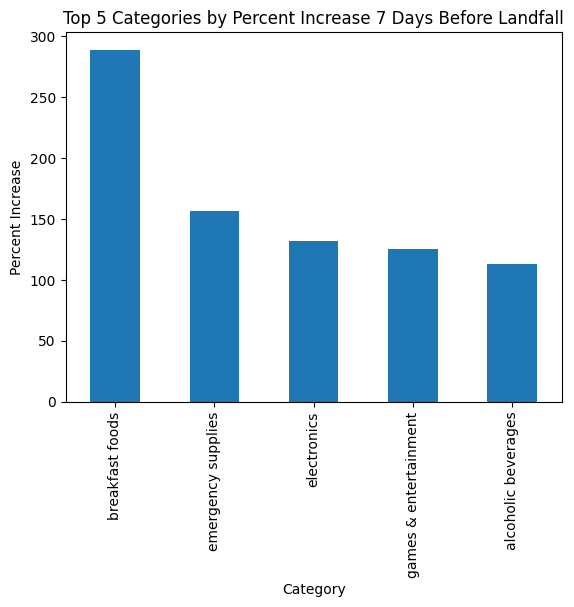

In [137]:
# visualization
import matplotlib.pyplot as plot

top5["percent_increase"].plot(kind="bar")
plot.xlabel("Category")
plot.ylabel("Percent Increase")
plot.title("Top 5 Categories by Percent Increase 7 Days Before Landfall")
plot.show()

Question 2: Pop Tart Consolidation

In [ ]:
import numpy as np

poptart_regex = r"pop[\s\-_]*tart"

all_poptarts = (
    df_product["product_name"].str.contains(poptart_regex, regex=True) |
    df_product["subcategory"].str.contains(poptart_regex, regex=True) |
    df_product_original["product_name"].str.contains(poptart_regex, regex=True)
)

sku_map = df_product.loc[all_poptarts, ["sku", "product_name", "package_size"]].copy()
sku_map["raw_product_name"] = df_product_original.loc[all_poptarts, "product_name"]
sku_map["standard_name"] = "poptarts"

df2 = df_transaction.copy()
df2["raw_sku"] = df_transaction_original["sku"].reindex(df2.index)
df2["raw_product_name"] = df_transaction_original["product_name"].reindex(df2.index)

df2 = df2.dropna(subset=["timestamp"]).copy()
df2["date"] = df2["timestamp"].dt.normalize()
df2["revenue"] = df2["quantity"]*df2["unit_price"]

x = df2[
    df2["raw_product_name"].str.contains(poptart_regex, regex=True)
    & ~df2["sku"].isin(sku_map["sku"])
]

if len(x):
  new_rows = pd.DataFrame({"sku": x["sku"].dropna().unique()})
  new_rows["standard_name"] = "poptarts"
  sku_map = pd.concat([sku_map, new_rows], ignore_index=True)

sku_map = sku_map.drop_duplicates(subset="sku")
print(sku_map)

df2["poptart"] = df2["sku"].isin(sku_map["sku"])
df2["clean"] = df2["sku"].map(sku_map.set_index("sku")["standard_name"])
df2["fragmented"] = np.where(df2["poptart"], df2["raw_sku"].astype(str), df2["product_name"])

In [ ]:
pop = df2[df2["poptart"]]

time = pd.date_range(df2["date"].min(), df2["date"].max(), freq="D")
days = len(time)

fragmented_sales = (
    pop.groupby(["date", "fragmented"])["quantity"].sum()
    .unstack("fragmented")
    .reindex(time)
    .fillna(0)
)

consol_sales = (
    pop.groupby("date")["quantity"].sum()
    .reindex(time)
    .fillna(0)
)

In [ ]:
frag_summary = pd.DataFrame({
    "total_units": fragmented_sales.sum(),
    "avg_daily_units": fragmented_sales.mean(),
})
frag_summary["share_of_total_%"] = frag_summary["total_units"] / frag_summary["total_units"].sum() * 100

consol_summary = pd.Series({
    "total_units": consol_sales.sum(),
    "avg_daily_units": consol_sales.mean(),
})

print("\nFragmented Summary (per SKU variant):")
print(frag_summary.round(2))
print("\nConsolidated Summary:")
print(consol_summary.round(2))

In [ ]:
# fragmented product ranking
f_rank = df2.groupby("fragmented").agg(total_units=("quantity", "sum"), total_revenue=("revenue", "sum"))
f_rank["avg_daily_units"] = f_rank["total_units"] / days
f_rank["unit_rank"] = f_rank["total_units"].rank(ascending=False, method="min").astype(int)
f_rank["revenue_rank"] = f_rank["total_revenue"].rank(ascending=False, method="min").astype(int)
rank_frag = f_rank.sort_values("total_units", ascending=False)

# consolidated product ranking
c_rank = df2.groupby("clean").agg(total_units=("quantity", "sum"), total_revenue=("revenue", "sum"))
c_rank["avg_daily_units"] = c_rank["total_units"] / days
c_rank["unit_rank"] = c_rank["total_units"].rank(ascending=False, method="min").astype(int)
c_rank["revenue_rank"] = c_rank["total_revenue"].rank(ascending=False, method="min").astype(int)
rank_consol = c_rank.sort_values("total_units", ascending=False)

# output
frag_poptart_ranks = rank_frag.loc[rank_frag.index.isin(fragmented_sales.columns)]
print(f"\nProducts in fragmented view: {len(rank_frag)} | in consolidated view: {len(rank_consol)}")
print("\nPop-Tart variants in the fragmented ranking:")
print(frag_poptart_ranks)
print("\nPop-Tarts in the consolidated ranking:")
print(rank_consol.loc[["poptarts"]])


In [ ]:
# visualization
import matplotlib.pyplot as plot
fig, (f1, f2) = plot.subplots(1, 2)

# fragmented
fragmented_sales.plot(ax=f1, title="Fragmented Sales")
f1.set_xlabel("Date")
f1.set_ylabel("Units Sold")
f1.set_ylim(0, 700)

# consolidated
consol_sales.plot(ax=f2, title="Consolidated Sales")
f2.set_xlabel("Date")
f2.set_ylabel("Units Sold")
f2.set_ylim(0, 700)

plot.tight_layout()
plot.show()

print("Fragmented total:", fragmented_sales.sum().sum())
print("Consolidated total:", consol_sales.sum())

Question 3: Weather vs Sales

In [ ]:
sales = df.dropna(subset=["timestamp", "category", "store_id"]).copy()
sales = sales[sales["store_id"].isin(weather_all["store_id"].unique())]
sales["date"] = sales["timestamp"].dt.normalize()

daily_cat = sales.groupby(["date", "category"])["quantity"].sum().unstack("category")

daily_weather = weather_all.groupby("date")[["windspeed_10m_max", "precipitation_sum"]].mean()
daily_cat = daily_cat.reindex(daily_weather.index).fillna(0)

# correlation table
corr_table = pd.DataFrame({
    w: daily_cat.apply(lambda s: s.corr(daily_weather[w], method="spearman"))
    for w in daily_weather.columns
})
print(corr_table.round(3))

# peak sales, peak weather conditions
wind_peak = daily_weather["windspeed_10m_max"].idxmax()
rain_peak = daily_weather["precipitation_sum"].idxmax()

timing = pd.DataFrame({"peak_sales_date": daily_cat.idxmax()})
timing["days_before_wind_peak"] = (wind_peak - timing["peak_sales_date"]).dt.days
timing["days_before_rain_peak"] = (rain_peak - timing["peak_sales_date"]).dt.days

print(timing)

In [ ]:
# visualization
daily_total = daily_cat.sum(axis=1)

# sales vs wind
plot.scatter(daily_weather["windspeed_10m_max"], daily_total)
plot.title("Daily Sales vs Wind Speed")
plot.xlabel("Max Wind Speed (km/h)")
plot.ylabel("Total units sold per day")
plot.show()

# sales vs rain
plot.scatter(daily_weather["precipitation_sum"], daily_total)
plot.title("Daily Sales vs Precipitation")
plot.xlabel("Total Precipitation (mm)")
plot.ylabel("Total units sold per day")
plot.show()